Part A -Classical and Foundational Modelling (tabular sensor data)
Using your chosen tabular dataset, implement and compare two models:
• ONE classical model of your choice: an ensemble method (bagging/Random Forest, or
boosting such as AdaBoost or Gradient Boosting) OR a kernel-based/probabilistic classifier
(a Support Vector Machine with an appropriate kernel, or Naïve Bayes).
• A simple feed-forward neural network (a small multi-layer perceptron trained via
backpropagation) – mandatory.
For each model, briefly justify your choice given the nature of the data, and evaluate both
models on the same held-out test split using appropriate metrics.

In [ ]:
# ============================================================
# PART A - CLASSICAL AND FOUNDATIONAL MODELLING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "ai4i" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/Advanced ML and NN r/ai4i+2020+predictive+maintenance+dataset.zip
/content/drive/MyDrive/Advanced ML and NN r/AI4I_Data/ai4i2020.csv


In [ ]:
import zipfile

zip_filename = "/content/drive/MyDrive/Advanced ML and NN r/ai4i+2020+predictive+maintenance+dataset.zip"

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    print("Files inside the ZIP:")

    for file_name in zip_ref.namelist():
        print(file_name)

Files inside the ZIP:
ai4i2020.csv


In [ ]:
extract_folder = "/content/drive/MyDrive/Advanced ML and NN r/AI4I_Data"

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully.")
print("Extracted files:", os.listdir(extract_folder))

Dataset extracted successfully.
Extracted files: ['ai4i2020.csv']


In [ ]:
import pandas as pd

csv_path = "/content/drive/MyDrive/Advanced ML and NN r/AI4I_Data/ai4i2020.csv"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Dataset Exploration

The dataset is initially examined to understand its dimensions, variable types,
data quality, and target distribution before preprocessing and model development.

In [ ]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Number of rows: 10000
Number of columns: 14

Column names:
1. UDI
2. Product ID
3. Type
4. Air temperature [K]
5. Process temperature [K]
6. Rotational speed [rpm]
7. Torque [Nm]
8. Tool wear [min]
9. Machine failure
10. TWF
11. HDF
12. PWF
13. OSF
14. RNF


In [ ]:
# Display variable types
print("DATA TYPES")
print("-" * 50)
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES")
print("-" * 50)
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

DATA TYPES
--------------------------------------------------
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

MISSING VALUES
--------------------------------------------------
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                

In [ ]:
duplicate_rows = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_rows)

Number of duplicated rows: 0


In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [ ]:
# Target class counts
failure_counts = df["Machine failure"].value_counts().sort_index()

# Target percentages
failure_percentages = (
    df["Machine failure"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

class_distribution = pd.DataFrame({
    "Count": failure_counts,
    "Percentage (%)": failure_percentages
})

class_distribution.index = ["No Failure (0)", "Failure (1)"]

display(class_distribution)

,Count,Percentage (%)
No Failure (0),9661,96.61
Failure (1),339,3.39


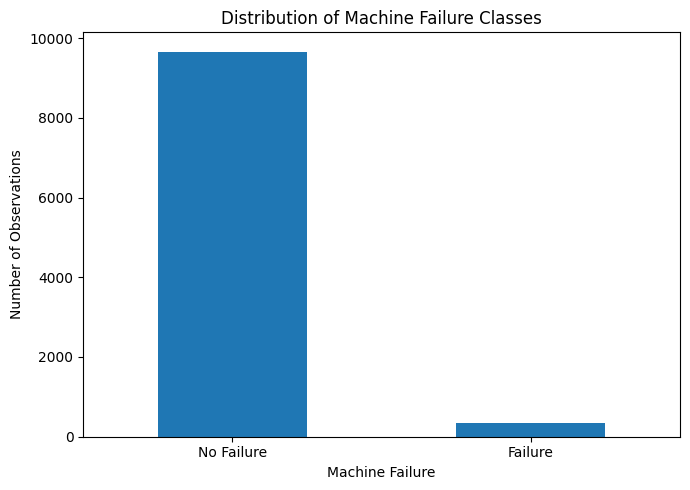

In [ ]:
plt.figure(figsize=(7, 5))

failure_counts.plot(kind="bar")

plt.title("Distribution of Machine Failure Classes")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Observations")
plt.xticks(
    ticks=[0, 1],
    labels=["No Failure", "Failure"],
    rotation=0
)

plt.tight_layout()
plt.show()

INVESTIGATING PRODUCT TYPES

In [ ]:
type_distribution = df["Type"].value_counts()

print("Product Type Distribution:")
print(type_distribution)

Product Type Distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


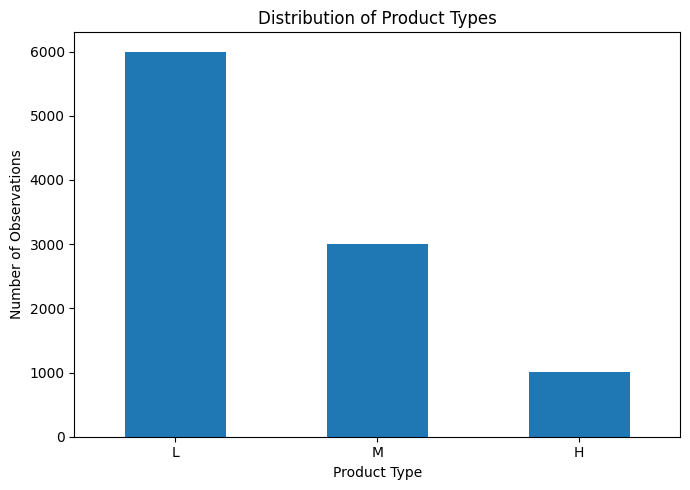

In [ ]:
plt.figure(figsize=(7, 5))

type_distribution.plot(kind="bar")

plt.title("Distribution of Product Types")
plt.xlabel("Product Type")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# 3. Feature Selection and Preprocessing

Identifier variables and failure-mode indicators are excluded from the predictive
feature set. The models use product type and physical operating measurements to
predict the binary Machine failure target.

In [ ]:
# Define predictor variables

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df["Machine failure"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Predictor shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


TRAIN-TEST SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTest target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training set: (8000, 6)
Test set: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64

Test target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


PREPROCESSING

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit ONLY using training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed test shape: (2000, 8)


## 4. Classical Machine Learning Model — Bagging Ensemble (Random Forest)



In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Baseline Random Forest
rf_baseline = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_baseline.fit(X_train_processed, y_train)

print("Baseline Random Forest trained successfully.")

Baseline Random Forest trained successfully.


In [ ]:
# Class predictions
y_pred_rf = rf_baseline.predict(X_test_processed)

# Probability of machine failure
y_prob_rf = rf_baseline.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)
rf_pr_auc = average_precision_score(y_test, y_prob_rf)

print("BASELINE RANDOM FOREST")
print("-" * 40)
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")
print(f"PR-AUC:    {rf_pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

BASELINE RANDOM FOREST
----------------------------------------
Accuracy:  0.9815
Precision: 0.8974
Recall:    0.5147
F1-score:  0.6542
ROC-AUC:   0.9721
PR-AUC:    0.7885

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.90      0.51      0.65        68

    accuracy                           0.98      2000
   macro avg       0.94      0.76      0.82      2000
weighted avg       0.98      0.98      0.98      2000



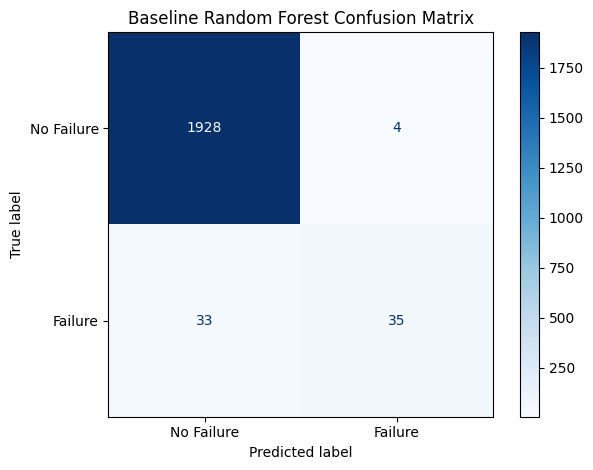

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Baseline Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

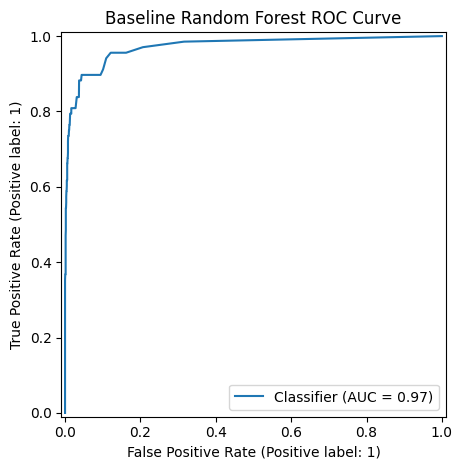

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf
)

plt.title("Baseline Random Forest ROC Curve")
plt.tight_layout()
plt.show()

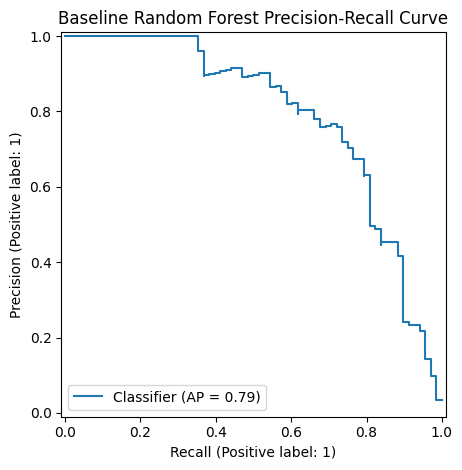

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_rf
)

plt.title("Baseline Random Forest Precision-Recall Curve")
plt.tight_layout()
plt.show()

### Random Forest Iteration — Class-Weighted Bagging Ensemble


In [ ]:
# Class-weighted Random Forest

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_processed, y_train)

print("Class-weighted Random Forest trained successfully.")

Class-weighted Random Forest trained successfully.


In [ ]:
y_pred_rf_balanced = rf_balanced.predict(X_test_processed)

y_prob_rf_balanced = rf_balanced.predict_proba(
    X_test_processed
)[:, 1]

In [ ]:
balanced_accuracy = accuracy_score(
    y_test, y_pred_rf_balanced
)

balanced_precision = precision_score(
    y_test, y_pred_rf_balanced,
    zero_division=0
)

balanced_recall = recall_score(
    y_test, y_pred_rf_balanced,
    zero_division=0
)

balanced_f1 = f1_score(
    y_test, y_pred_rf_balanced,
    zero_division=0
)

balanced_roc_auc = roc_auc_score(
    y_test, y_prob_rf_balanced
)

balanced_pr_auc = average_precision_score(
    y_test, y_prob_rf_balanced
)

print("CLASS-WEIGHTED RANDOM FOREST")
print("-" * 40)

print(f"Accuracy:  {balanced_accuracy:.4f}")
print(f"Precision: {balanced_precision:.4f}")
print(f"Recall:    {balanced_recall:.4f}")
print(f"F1-score:  {balanced_f1:.4f}")
print(f"ROC-AUC:   {balanced_roc_auc:.4f}")
print(f"PR-AUC:    {balanced_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf_balanced,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

CLASS-WEIGHTED RANDOM FOREST
----------------------------------------
Accuracy:  0.9790
Precision: 0.9062
Recall:    0.4265
F1-score:  0.5800
ROC-AUC:   0.9636
PR-AUC:    0.7720

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.91      0.43      0.58        68

    accuracy                           0.98      2000
   macro avg       0.94      0.71      0.78      2000
weighted avg       0.98      0.98      0.98      2000



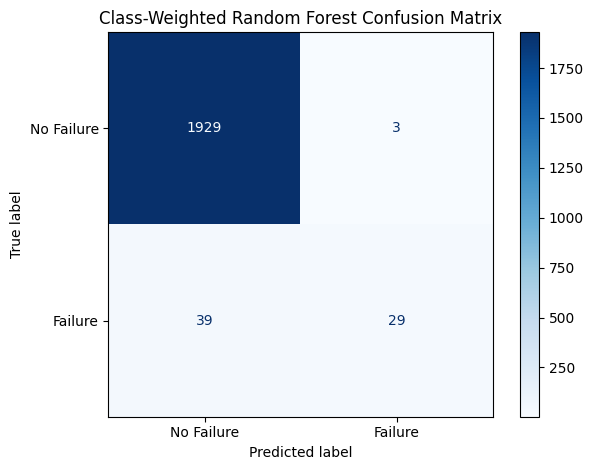

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_balanced,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Class-Weighted Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
rf_comparison = pd.DataFrame({
    "Baseline RF (Bagging)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ],

    "Class-Weighted RF (Bagging)": [
        balanced_accuracy,
        balanced_precision,
        balanced_recall,
        balanced_f1,
        balanced_roc_auc,
        balanced_pr_auc
    ]
},
index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
])

display(rf_comparison.round(4))

,Baseline RF (Bagging),Class-Weighted RF (Bagging)
Accuracy,0.9815,0.9790
Precision,0.8974,0.9062
Recall,0.5147,0.4265
F1-score,0.6542,0.5800
ROC-AUC,0.9721,0.9636
PR-AUC,0.7885,0.7720


## Feature importance



In [ ]:
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

feature_names

array(['num__Air temperature [K]', 'num__Process temperature [K]',
       'num__Rotational speed [rpm]', 'num__Torque [Nm]',
       'num__Tool wear [min]', 'cat__Type_H', 'cat__Type_L',
       'cat__Type_M'], dtype=object)

In [ ]:
# Random Forest feature importance

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_baseline.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance)

,Feature,Importance
3,num__Torque [Nm],0.315965
2,num__Rotational speed [rpm],0.236100
4,num__Tool wear [min],0.167303
0,num__Air temperature [K],0.132306
1,num__Process temperature [K],0.123830
6,cat__Type_L,0.010970
7,cat__Type_M,0.008307
5,cat__Type_H,0.005220


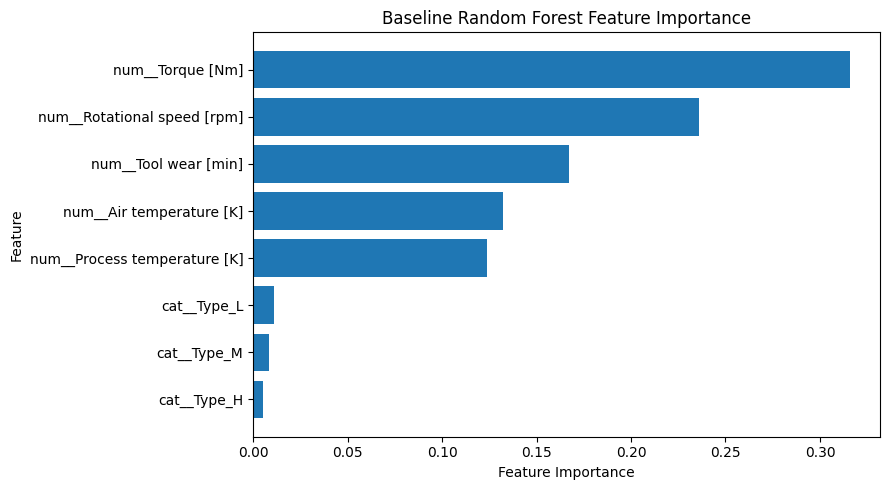

In [ ]:
plt.figure(figsize=(9, 5))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Baseline Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
## Creating a validation set ##
from sklearn.model_selection import train_test_split

X_mlp_train, X_mlp_val, y_mlp_train, y_mlp_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("MLP training set:", X_mlp_train.shape)
print("MLP validation set:", X_mlp_val.shape)
print("Final test set:", X_test_processed.shape)

print("\nMLP training class distribution:")
print(y_mlp_train.value_counts())

print("\nMLP validation class distribution:")
print(y_mlp_val.value_counts())

MLP training set: (6400, 8)
MLP validation set: (1600, 8)
Final test set: (2000, 8)

MLP training class distribution:
Machine failure
0    6183
1     217
Name: count, dtype: int64

MLP validation class distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64


## 5. Feed-Forward Neural Network



In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

mlp_model = Sequential([
    Input(shape=(X_mlp_train.shape[1],)),

    Dense(32, activation="relu"),
    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
mlp_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
## Training a baseline MLP ##

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_baseline = mlp_model.fit(
    X_mlp_train,
    y_mlp_train,
    validation_data=(X_mlp_val, y_mlp_val),
    epochs=40,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9292 - loss: 0.2869 - val_accuracy: 0.9663 - val_loss: 0.1504
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9661 - loss: 0.1342 - val_accuracy: 0.9669 - val_loss: 0.1190
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9680 - loss: 0.1097 - val_accuracy: 0.9700 - val_loss: 0.0981
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9695 - loss: 0.0971 - val_accuracy: 0.9744 - val_loss: 0.0908
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9712 - loss: 0.0907 - val_accuracy: 0.9769 - val_loss: 0.0867
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9716 - loss: 0.0859 - val_accuracy: 0.9775 - val_loss: 0.0834
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9719 - loss: 0.0820 - val_accuracy: 0.9787 - val_loss: 0.0811
Epoch 8/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9720 - loss: 0.0788 - val_accuracy: 0.

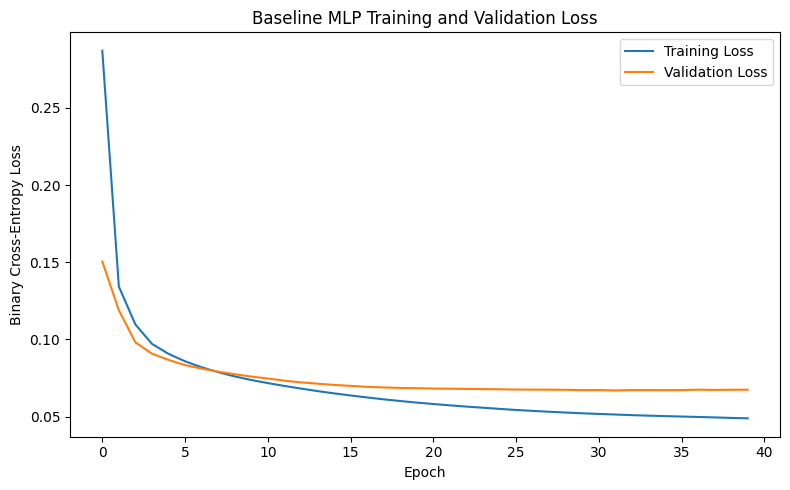

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_baseline.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_baseline.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Baseline MLP Training and Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

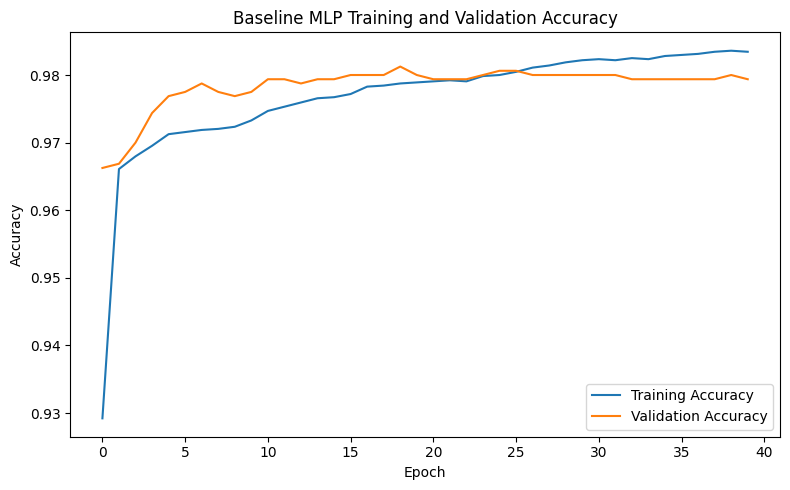

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_baseline.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_baseline.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline MLP Training and Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Predicted probabilities
y_prob_mlp = mlp_model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Convert probabilities to classes using threshold = 0.5
y_pred_mlp = (y_prob_mlp >= 0.5).astype(int)

In [ ]:
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(
    y_test, y_pred_mlp, zero_division=0
)
mlp_recall = recall_score(
    y_test, y_pred_mlp, zero_division=0
)
mlp_f1 = f1_score(
    y_test, y_pred_mlp, zero_division=0
)
mlp_roc_auc = roc_auc_score(
    y_test, y_prob_mlp
)
mlp_pr_auc = average_precision_score(
    y_test, y_prob_mlp
)

print("BASELINE MLP")
print("-" * 40)

print(f"Accuracy:  {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall:    {mlp_recall:.4f}")
print(f"F1-score:  {mlp_f1:.4f}")
print(f"ROC-AUC:   {mlp_roc_auc:.4f}")
print(f"PR-AUC:    {mlp_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_mlp,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

BASELINE MLP
----------------------------------------
Accuracy:  0.9760
Precision: 0.7381
Recall:    0.4559
F1-score:  0.5636
ROC-AUC:   0.9709
PR-AUC:    0.7042

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1932
     Failure       0.74      0.46      0.56        68

    accuracy                           0.98      2000
   macro avg       0.86      0.73      0.78      2000
weighted avg       0.97      0.98      0.97      2000



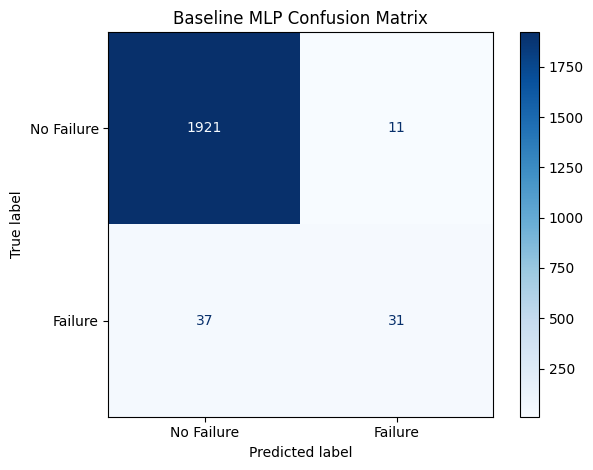

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Baseline MLP Confusion Matrix")
plt.tight_layout()
plt.show()

### MLP Iteration-Class-Weighted MLP

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_mlp_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_mlp_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(0.5175481158013909), np.int64(1): np.float64(14.746543778801843)}


A fresh MLP with the same architecture is initialised to provide a fair comparison with the baseline model.

In [ ]:
tf.keras.backend.clear_session()

np.random.seed(42)
tf.random.set_seed(42)

mlp_weighted = Sequential([
    Input(shape=(X_mlp_train.shape[1],)),

    Dense(32, activation="relu"),
    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

mlp_weighted.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

mlp_weighted.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping_weighted = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_weighted = mlp_weighted.fit(
    X_mlp_train,
    y_mlp_train,
    validation_data=(X_mlp_val, y_mlp_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping_weighted],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6075 - loss: 0.5617 - val_accuracy: 0.7594 - val_loss: 0.5577
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8123 - loss: 0.4152 - val_accuracy: 0.8413 - val_loss: 0.4145
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8495 - loss: 0.3542 - val_accuracy: 0.8644 - val_loss: 0.3659
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8633 - loss: 0.3240 - val_accuracy: 0.8681 - val_loss: 0.3387
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8706 - loss: 0.3029 - val_accuracy: 0.8737 - val_loss: 0.3205
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8777 - loss: 0.2869 - val_accuracy: 0.8731 - val_loss: 0.3086
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8838 - loss: 0.2741 - val_accuracy: 0.8750 - val_loss: 0.2985
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8867 - loss: 0.2635 - val_accuracy: 0

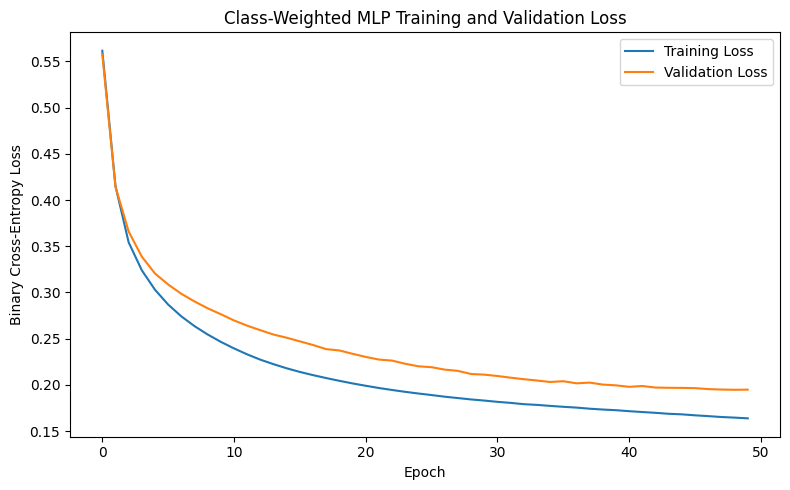

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_weighted.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_weighted.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Class-Weighted MLP Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

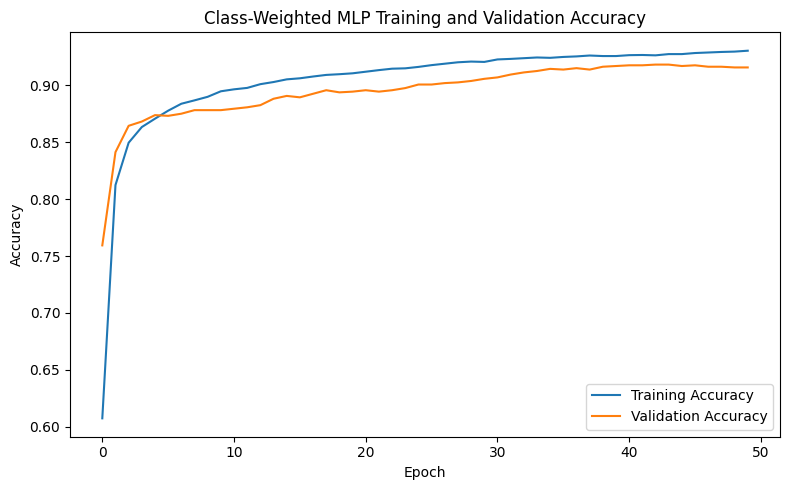

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_weighted.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_weighted.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Class-Weighted MLP Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
y_prob_mlp_weighted = mlp_weighted.predict(
    X_test_processed,
    verbose=0
).ravel()

y_pred_mlp_weighted = (
    y_prob_mlp_weighted >= 0.5
).astype(int)


weighted_mlp_accuracy = accuracy_score(
    y_test, y_pred_mlp_weighted
)

weighted_mlp_precision = precision_score(
    y_test, y_pred_mlp_weighted,
    zero_division=0
)

weighted_mlp_recall = recall_score(
    y_test, y_pred_mlp_weighted,
    zero_division=0
)

weighted_mlp_f1 = f1_score(
    y_test, y_pred_mlp_weighted,
    zero_division=0
)

weighted_mlp_roc_auc = roc_auc_score(
    y_test, y_prob_mlp_weighted
)

weighted_mlp_pr_auc = average_precision_score(
    y_test, y_prob_mlp_weighted
)


print("CLASS-WEIGHTED MLP")
print("-" * 40)

print(f"Accuracy:  {weighted_mlp_accuracy:.4f}")
print(f"Precision: {weighted_mlp_precision:.4f}")
print(f"Recall:    {weighted_mlp_recall:.4f}")
print(f"F1-score:  {weighted_mlp_f1:.4f}")
print(f"ROC-AUC:   {weighted_mlp_roc_auc:.4f}")
print(f"PR-AUC:    {weighted_mlp_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_mlp_weighted,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

CLASS-WEIGHTED MLP
----------------------------------------
Accuracy:  0.9225
Precision: 0.2857
Recall:    0.8529
F1-score:  0.4280
ROC-AUC:   0.9621
PR-AUC:    0.6634

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.92      0.96      1932
     Failure       0.29      0.85      0.43        68

    accuracy                           0.92      2000
   macro avg       0.64      0.89      0.69      2000
weighted avg       0.97      0.92      0.94      2000



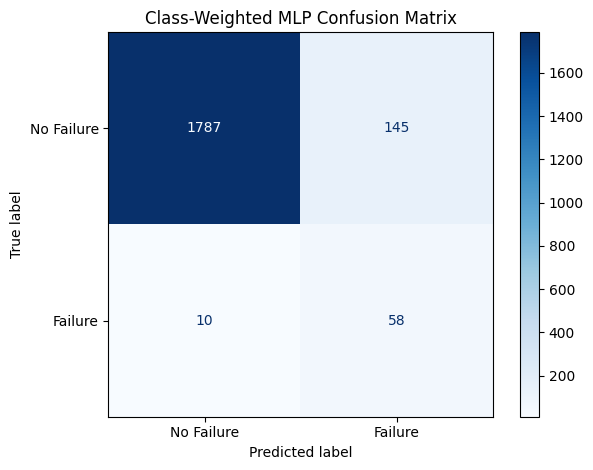

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp_weighted,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Class-Weighted MLP Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
model_comparison = pd.DataFrame({
    "Baseline RF": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ],

    "Weighted RF": [
        balanced_accuracy,
        balanced_precision,
        balanced_recall,
        balanced_f1,
        balanced_roc_auc,
        balanced_pr_auc
    ],

    "Baseline MLP": [
        mlp_accuracy,
        mlp_precision,
        mlp_recall,
        mlp_f1,
        mlp_roc_auc,
        mlp_pr_auc
    ],

    "Weighted MLP": [
        weighted_mlp_accuracy,
        weighted_mlp_precision,
        weighted_mlp_recall,
        weighted_mlp_f1,
        weighted_mlp_roc_auc,
        weighted_mlp_pr_auc
    ]
},
index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
])

display(model_comparison.round(4))

,Baseline RF,Weighted RF,Baseline MLP,Weighted MLP
Accuracy,0.9815,0.9790,0.9760,0.9225
Precision,0.8974,0.9062,0.7381,0.2857
Recall,0.5147,0.4265,0.4559,0.8529
F1-score,0.6542,0.5800,0.5636,0.4280
ROC-AUC,0.9721,0.9636,0.9709,0.9621
PR-AUC,0.7885,0.7720,0.7042,0.6634


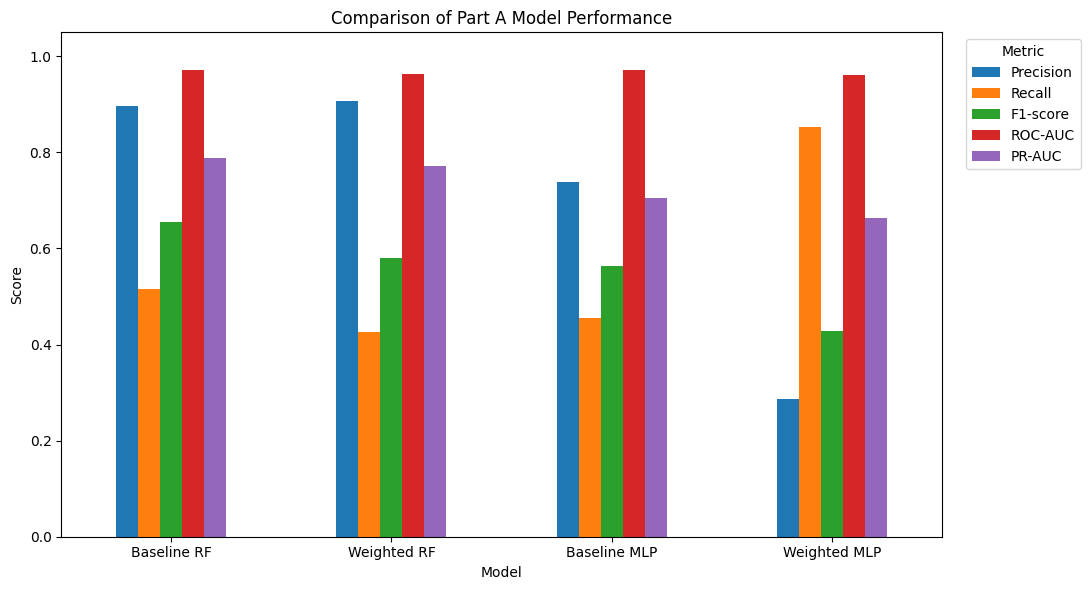

In [ ]:
## Comparison Figure ##
comparison_plot = model_comparison.T[
    ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Part A Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Part B — Convolutional Neural Networks

This section investigates visual quality inspection using the Casting Product
Image Dataset. A convolutional neural network is developed from scratch for
binary classification of defective and non-defective cast products.

In [ ]:
import os

part_b_zip = "/content/drive/MyDrive/Advanced ML and NN r/archive.zip"

print("File exists:", os.path.exists(part_b_zip))

File exists: True


In [ ]:
import zipfile

with zipfile.ZipFile(part_b_zip, "r") as zip_ref:
    file_list = zip_ref.namelist()

print("Number of files in ZIP:", len(file_list))

print("\nFirst 20 entries:")
for file_name in file_list[:20]:
    print(file_name)

Number of files in ZIP: 8648

First 20 entries:
casting_512x512/casting_512x512/def_front/cast_def_0_0.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_100.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1015.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_102.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1046.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1053.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1055.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1077.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1087.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1091.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1104.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1108.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1112.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1115.jpeg
casting_512x512/casting_512x512/def_front/cast_def_0_1123.jpeg
casting_512x

In [ ]:
part_b_folder = "/content/drive/MyDrive/Advanced ML and NN r/Part_B_Casting"

if not os.path.exists(part_b_folder):
    with zipfile.ZipFile(part_b_zip, "r") as zip_ref:
        zip_ref.extractall(part_b_folder)

    print("Dataset extracted successfully.")

else:
    print("Dataset folder already exists.")

Dataset folder already exists.


In [ ]:
for root, dirs, files in os.walk(part_b_folder):
    level = root.replace(part_b_folder, "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:3]:
            print(f"{indent}    {file}")

Part_B_Casting/
    casting_512x512/
        casting_512x512/
            def_front/
                cast_def_0_0.jpeg
                cast_def_0_100.jpeg
                cast_def_0_1015.jpeg
            ok_front/
                cast_ok_0_1018.jpeg
                cast_ok_0_1021.jpeg
                cast_ok_0_1028.jpeg
    casting_data/
        casting_data/
            test/
            train/


In [ ]:
train_dir = "/content/drive/MyDrive/Advanced ML and NN r/Part_B_Casting/casting_data/casting_data/train"

test_dir = "/content/drive/MyDrive/Advanced ML and NN r/Part_B_Casting/casting_data/casting_data/test"

print("Training folders:")
print(os.listdir(train_dir))

print("\nTest folders:")
print(os.listdir(test_dir))

Training folders:
['def_front', 'ok_front']

Test folders:
['def_front', 'ok_front']


In [ ]:
train_defective = len(
    os.listdir(os.path.join(train_dir, "def_front"))
)

train_ok = len(
    os.listdir(os.path.join(train_dir, "ok_front"))
)

test_defective = len(
    os.listdir(os.path.join(test_dir, "def_front"))
)

test_ok = len(
    os.listdir(os.path.join(test_dir, "ok_front"))
)

print("TRAINING DATA")
print("-" * 30)
print("Defective:", train_defective)
print("OK:", train_ok)
print("Total:", train_defective + train_ok)

print("\nTEST DATA")
print("-" * 30)
print("Defective:", test_defective)
print("OK:", test_ok)
print("Total:", test_defective + test_ok)

print("\nTOTAL IMAGES:",
      train_defective + train_ok +
      test_defective + test_ok)

TRAINING DATA
------------------------------
Defective: 3758
OK: 2875
Total: 6633

TEST DATA
------------------------------
Defective: 453
OK: 262
Total: 715

TOTAL IMAGES: 7348


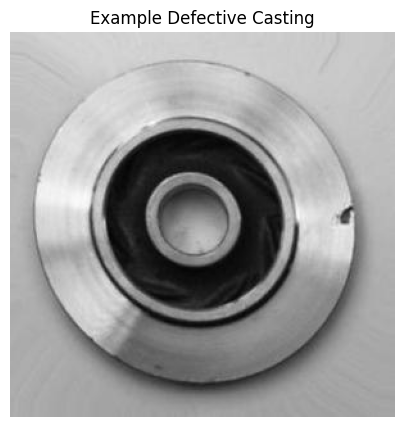

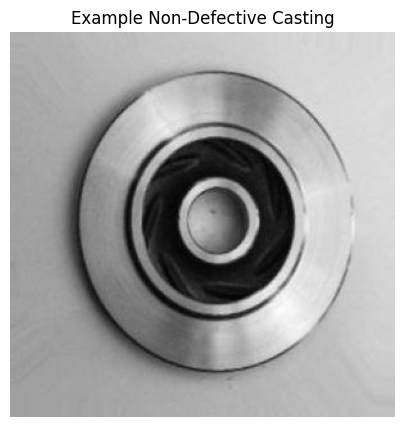

Defective image size: (300, 300)
OK image size: (300, 300)
Defective image mode: RGB
OK image mode: RGB


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Paths to the two training classes
defective_folder = os.path.join(train_dir, "def_front")
ok_folder = os.path.join(train_dir, "ok_front")

# Select one random image from each class
defective_file = random.choice(os.listdir(defective_folder))
ok_file = random.choice(os.listdir(ok_folder))

# Load images
defective_image = Image.open(
    os.path.join(defective_folder, defective_file)
)

ok_image = Image.open(
    os.path.join(ok_folder, ok_file)
)

# Display defective image
plt.figure(figsize=(5, 5))
plt.imshow(defective_image, cmap="gray")
plt.title("Example Defective Casting")
plt.axis("off")
plt.show()

# Display OK image
plt.figure(figsize=(5, 5))
plt.imshow(ok_image, cmap="gray")
plt.title("Example Non-Defective Casting")
plt.axis("off")
plt.show()

# Image information
print("Defective image size:", defective_image.size)
print("OK image size:", ok_image.size)

print("Defective image mode:", defective_image.mode)
print("OK image mode:", ok_image.mode)

In [ ]:
import tensorflow as tf

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
SEED = 42

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 6633 files belonging to 2 classes.
Using 5307 files for training.


In [ ]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 6633 files belonging to 2 classes.
Using 1326 files for validation.


In [ ]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

Found 715 files belonging to 2 classes.


In [ ]:
class_names = train_dataset.class_names

print("Class names:", class_names)

for index, class_name in enumerate(class_names):
    print(f"{index} = {class_name}")

Class names: ['def_front', 'ok_front']
0 = def_front
1 = ok_front


In [ ]:
for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("\nMinimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32, 1)

Minimum pixel value: 0.0
Maximum pixel value: 254.94897


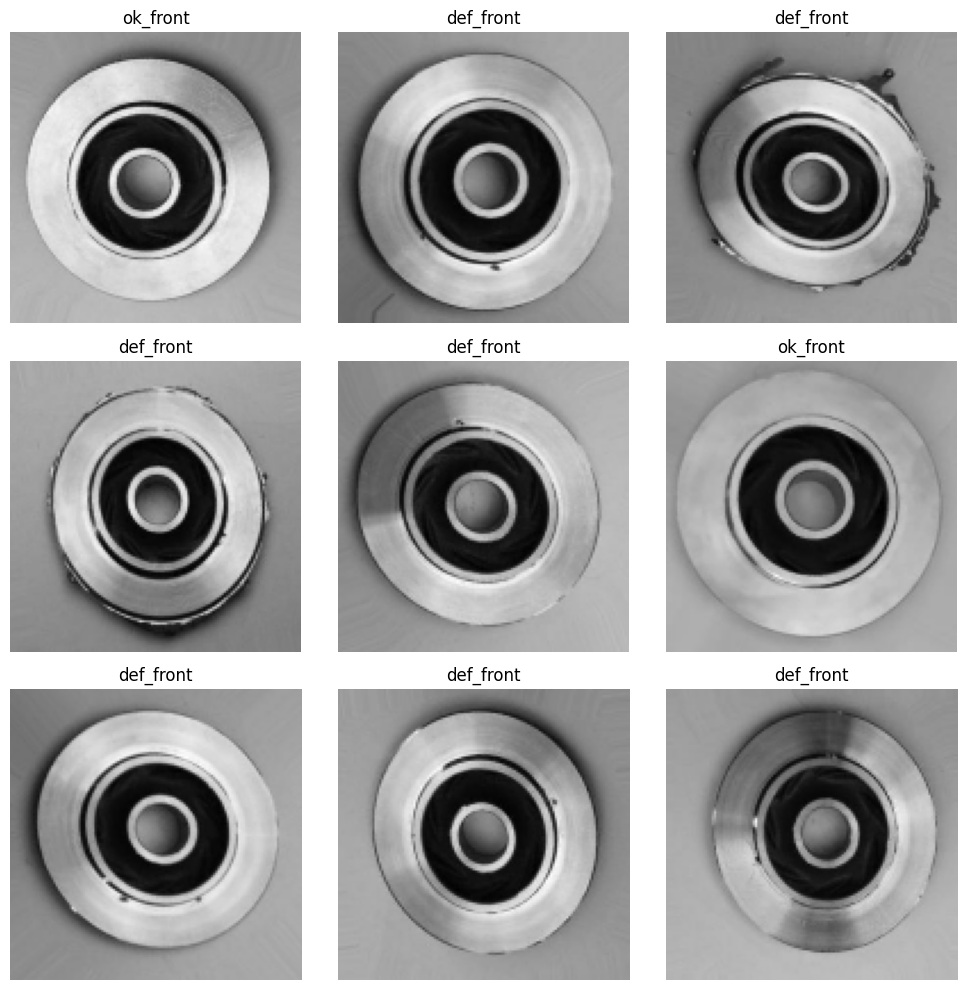

In [ ]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])

        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

## Baseline CNN

A baseline convolutional neural network is constructed from scratch. Three
convolutional blocks are used to progressively learn spatial features from the
casting images. Max-pooling reduces the spatial dimensions after each
convolutional layer. A sigmoid output unit performs binary classification.

In [ ]:
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()
tf.random.set_seed(42)

baseline_cnn = models.Sequential([

    # Input
    layers.Input(shape=(128, 128, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),

    # Convolutional Block 1
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolutional Block 2
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolutional Block 3
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
baseline_cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

cnn_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history_cnn_baseline = baseline_cnn.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[cnn_early_stopping],
    verbose=1
)

Epoch 1/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 623s 3s/step - accuracy: 0.6783 - loss: 0.5896 - val_accuracy: 0.8544 - val_loss: 0.3425
Epoch 2/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step - accuracy: 0.8883 - loss: 0.2680 - val_accuracy: 0.9427 - val_loss: 0.1948
Epoch 3/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9444 - loss: 0.1510 - val_accuracy: 0.9389 - val_loss: 0.1689
Epoch 4/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9717 - loss: 0.0957 - val_accuracy: 0.9465 - val_loss: 0.1378
Epoch 5/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.9796 - loss: 0.0727 - val_accuracy: 0.9449 - val_loss: 0.1780
Epoch 6/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.9781 - loss: 0.0659 - val_accuracy: 0.9472 - val_loss: 0.1404
Epoch 7/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.9851 - loss: 0.0453 - val_accuracy: 0.9751 - val_loss: 0.0755
Epoch 8/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 86ms/step - accuracy: 0.9917 - loss: 0.0280 - v

From Epochs 1–19, we can already see training accuracy rising to ~99%+ while validation accuracy reaches ~98–99%. The validation loss fluctuates while training loss becomes extremely small, so the learning curves will be important for assessing whether some overfitting starts appearing. That is exactly what Part B asks you to examine.

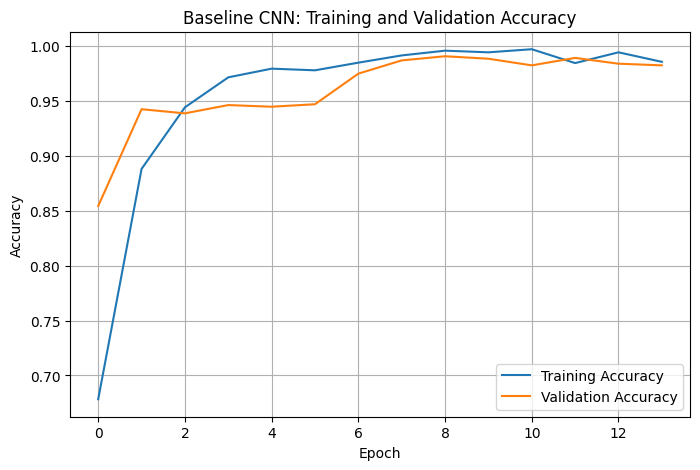

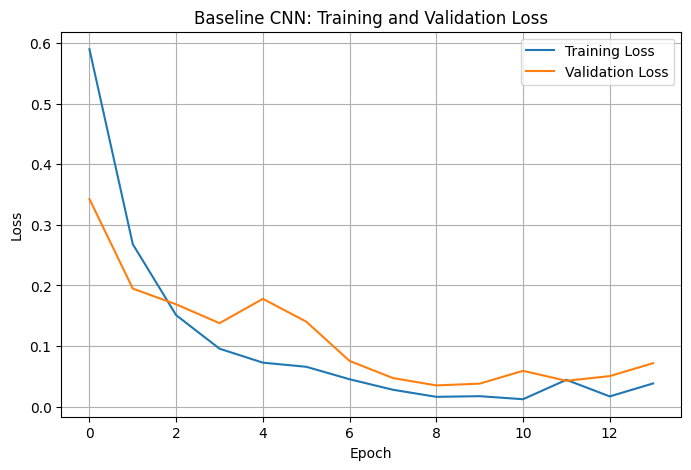

In [ ]:
import matplotlib.pyplot as plt

# Extract training history
history = history_cnn_baseline.history

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN: Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Obtain true test labels
y_test_cnn = np.concatenate([
    y.numpy() for x, y in test_dataset
])

# Obtain predicted probabilities
y_prob_cnn_baseline = baseline_cnn.predict(test_dataset).ravel()

# Convert probabilities to binary predictions
y_pred_cnn_baseline = (y_prob_cnn_baseline >= 0.5).astype(int)

# Calculate evaluation metrics
cnn_baseline_accuracy = accuracy_score(y_test_cnn, y_pred_cnn_baseline)
cnn_baseline_precision = precision_score(y_test_cnn, y_pred_cnn_baseline)
cnn_baseline_recall = recall_score(y_test_cnn, y_pred_cnn_baseline)
cnn_baseline_f1 = f1_score(y_test_cnn, y_pred_cnn_baseline)
cnn_baseline_roc_auc = roc_auc_score(y_test_cnn, y_prob_cnn_baseline)
cnn_baseline_pr_auc = average_precision_score(y_test_cnn, y_prob_cnn_baseline)

print("Baseline CNN Test Performance")
print("--------------------------------")
print(f"Accuracy : {cnn_baseline_accuracy:.4f}")
print(f"Precision: {cnn_baseline_precision:.4f}")
print(f"Recall   : {cnn_baseline_recall:.4f}")
print(f"F1-score : {cnn_baseline_f1:.4f}")
print(f"ROC-AUC  : {cnn_baseline_roc_auc:.4f}")
print(f"PR-AUC   : {cnn_baseline_pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_cnn, y_pred_cnn_baseline))

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step
Baseline CNN Test Performance
--------------------------------
Accuracy : 0.9972
Precision: 0.9924
Recall   : 1.0000
F1-score : 0.9962
ROC-AUC  : 1.0000
PR-AUC   : 1.0000

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       453
         1.0       0.99      1.00      1.00       262

    accuracy                           1.00       715
   macro avg       1.00      1.00      1.00       715
weighted avg       1.00      1.00      1.00       715



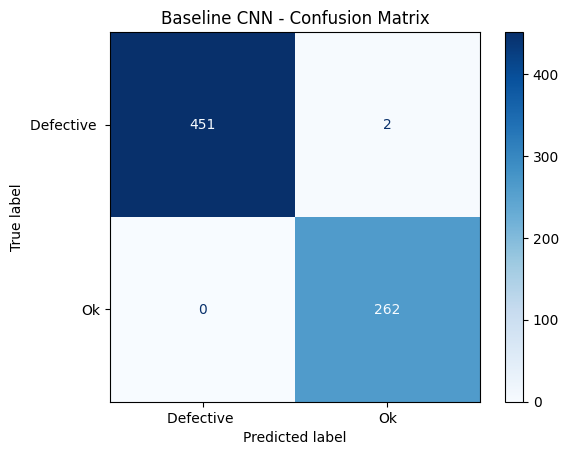

[[451   2]
 [  0 262]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_cnn, y_pred_cnn_baseline)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Defective ", "Ok"]
)

disp.plot(cmap="Blues")
plt.title("Baseline CNN - Confusion Matrix")
plt.show()

print(cm)

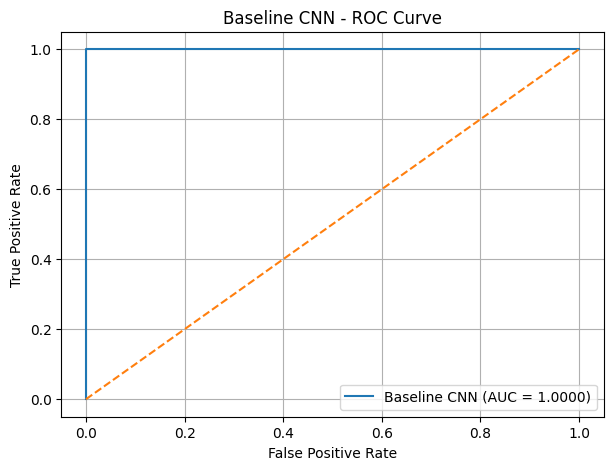

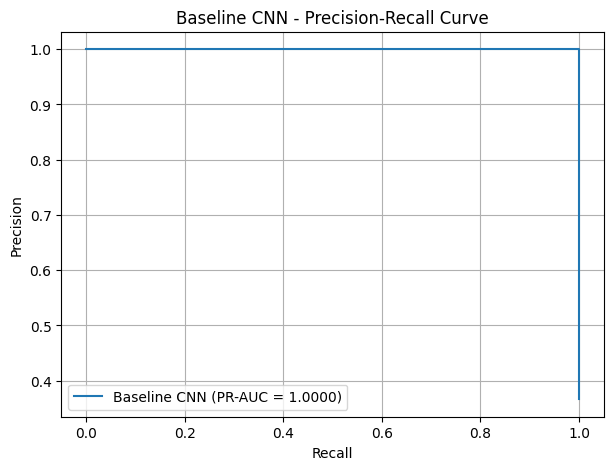

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

# ROC curve
fpr, tpr, _ = roc_curve(y_test_cnn, y_prob_cnn_baseline)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"Baseline CNN (AUC = {cnn_baseline_roc_auc:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline CNN - ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


# Precision-Recall curve
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test_cnn,
    y_prob_cnn_baseline
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_curve,
    precision_curve,
    label=f"Baseline CNN (PR-AUC = {cnn_baseline_pr_auc:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Baseline CNN - Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

# CNN v2 - architectural iteration
cnn_v2 = Sequential([
    Input(shape=(128, 128, 3)),
    Rescaling(1./255),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

cnn_v2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

cnn_v2_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cnn_v2 = cnn_v2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[cnn_v2_early_stopping],
    verbose=1
)

Epoch 1/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 113ms/step - accuracy: 0.5679 - loss: 0.6874 - val_accuracy: 0.5581 - val_loss: 0.6848
Epoch 2/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 16s 96ms/step - accuracy: 0.5674 - loss: 0.6796 - val_accuracy: 0.5581 - val_loss: 0.6613
Epoch 3/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 85ms/step - accuracy: 0.7155 - loss: 0.5809 - val_accuracy: 0.7564 - val_loss: 0.5435
Epoch 4/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 86ms/step - accuracy: 0.7912 - loss: 0.4767 - val_accuracy: 0.7964 - val_loss: 0.4652
Epoch 5/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 85ms/step - accuracy: 0.8575 - loss: 0.3714 - val_accuracy: 0.9163 - val_loss: 0.2939
Epoch 6/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 21s 87ms/step - accuracy: 0.8792 - loss: 0.3338 - val_accuracy: 0.9261 - val_loss: 0.2411
Epoch 7/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 85ms/step - accuracy: 0.9212 - loss: 0.2526 - val_accuracy: 0.9487 - val_loss: 0.1918
Epoch 8/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9423 - loss: 0.2012 -

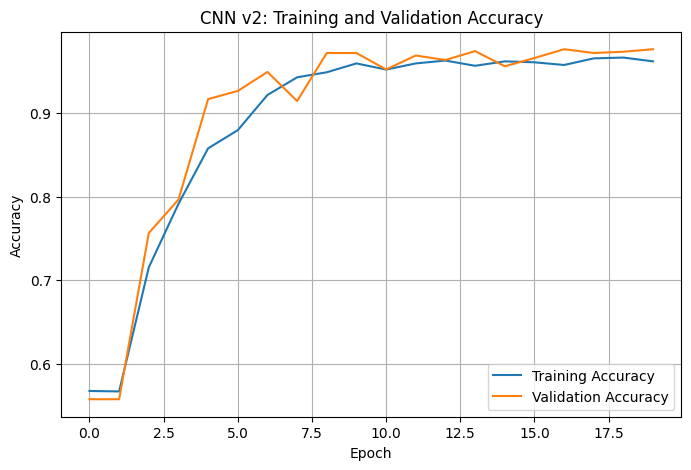

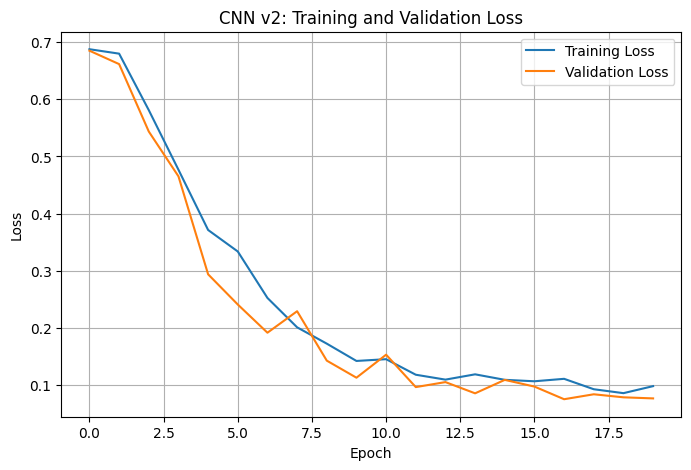

In [ ]:
import matplotlib.pyplot as plt

history_v2 = history_cnn_v2.history

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_v2["accuracy"], label="Training Accuracy")
plt.plot(history_v2["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN v2: Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(history_v2["loss"], label="Training Loss")
plt.plot(history_v2["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN v2: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Predict probabilities on the SAME held-out test set
y_prob_cnn_v2 = cnn_v2.predict(test_dataset).ravel()

# Convert probabilities to binary predictions
y_pred_cnn_v2 = (y_prob_cnn_v2 >= 0.5).astype(int)

# Calculate evaluation metrics
cnn_v2_accuracy = accuracy_score(y_test_cnn, y_pred_cnn_v2)
cnn_v2_precision = precision_score(y_test_cnn, y_pred_cnn_v2)
cnn_v2_recall = recall_score(y_test_cnn, y_pred_cnn_v2)
cnn_v2_f1 = f1_score(y_test_cnn, y_pred_cnn_v2)
cnn_v2_roc_auc = roc_auc_score(y_test_cnn, y_prob_cnn_v2)
cnn_v2_pr_auc = average_precision_score(y_test_cnn, y_prob_cnn_v2)

print("CNN v2 Test Performance")
print("--------------------------------")
print(f"Accuracy : {cnn_v2_accuracy:.4f}")
print(f"Precision: {cnn_v2_precision:.4f}")
print(f"Recall   : {cnn_v2_recall:.4f}")
print(f"F1-score : {cnn_v2_f1:.4f}")
print(f"ROC-AUC  : {cnn_v2_roc_auc:.4f}")
print(f"PR-AUC   : {cnn_v2_pr_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_cnn,
        y_pred_cnn_v2,
        target_names=["Defective", "OK"],
        digits=4
    )
)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step
CNN v2 Test Performance
--------------------------------
Accuracy : 0.9818
Precision: 0.9844
Recall   : 0.9656
F1-score : 0.9750
ROC-AUC  : 0.9970
PR-AUC   : 0.9954

Classification Report:
              precision    recall  f1-score   support

   Defective     0.9803    0.9912    0.9857       453
          OK     0.9844    0.9656    0.9750       262

    accuracy                         0.9818       715
   macro avg     0.9824    0.9784    0.9803       715
weighted avg     0.9818    0.9818    0.9818       715



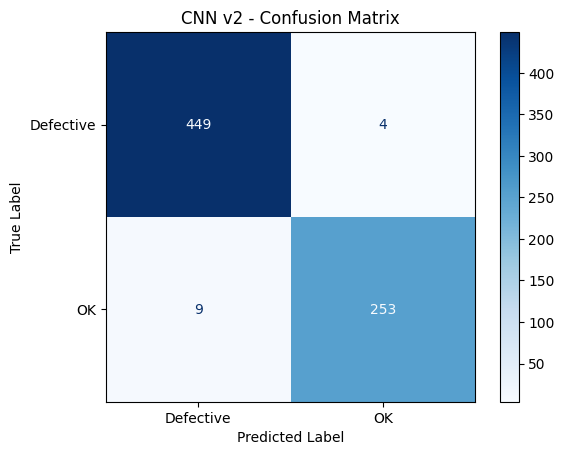

[[449   4]
 [  9 253]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_v2 = confusion_matrix(y_test_cnn, y_pred_cnn_v2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=["Defective", "OK"]
)

disp.plot(cmap="Blues")
plt.title("CNN v2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print(cm_v2)

CNN vs CNN-V2 Comparison Cell

In [ ]:
import pandas as pd

cnn_comparison = pd.DataFrame({
    "Baseline CNN": [
        cnn_baseline_accuracy,
        cnn_baseline_precision,
        cnn_baseline_recall,
        cnn_baseline_f1,
        cnn_baseline_roc_auc,
        cnn_baseline_pr_auc
    ],

    "CNN v2": [
        cnn_v2_accuracy,
        cnn_v2_precision,
        cnn_v2_recall,
        cnn_v2_f1,
        cnn_v2_roc_auc,
        cnn_v2_pr_auc
    ]
},
index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
])

display(cnn_comparison.round(4))

,Baseline CNN,CNN v2
Accuracy,0.9972,0.9818
Precision,0.9924,0.9844
Recall,1.0000,0.9656
F1-score,0.9962,0.9750
ROC-AUC,1.0000,0.9970
PR-AUC,1.0000,0.9954


FINAL PREDICTIVE PERFORMANCE TABLE:

In [ ]:
import pandas as pd

final_model_comparison = pd.DataFrame({
    "Random Forest (Bagging)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ],

    "Feed-Forward MLP": [
        mlp_accuracy,
        mlp_precision,
        mlp_recall,
        mlp_f1,
        mlp_roc_auc,
        mlp_pr_auc
    ],

    "Baseline CNN": [
        cnn_baseline_accuracy,
        cnn_baseline_precision,
        cnn_baseline_recall,
        cnn_baseline_f1,
        cnn_baseline_roc_auc,
        cnn_baseline_pr_auc
    ]
},
index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
])

display(final_model_comparison.round(4))

,Random Forest (Bagging),Feed-Forward MLP,Baseline CNN
Accuracy,0.9815,0.9760,0.9972
Precision,0.8974,0.7381,0.9924
Recall,0.5147,0.4559,1.0000
F1-score,0.6542,0.5636,0.9962
ROC-AUC,0.9721,0.9709,1.0000
PR-AUC,0.7885,0.7042,1.0000


PERFORMANCE COMPARISON FIGURES:

# Part C — Critical Comparison

The final selected models from Parts A and B are compared in terms of predictive
performance, interpretability, data and computational requirements, training cost,
and suitability for deployment in the SmartFactory scenario.

The final models selected for comparison are:
- Random Forest (Bagging) for tabular sensor data
- Feed-Forward MLP for tabular sensor data
- Baseline CNN for image-based defect classification

##Predictive Performance Comparison

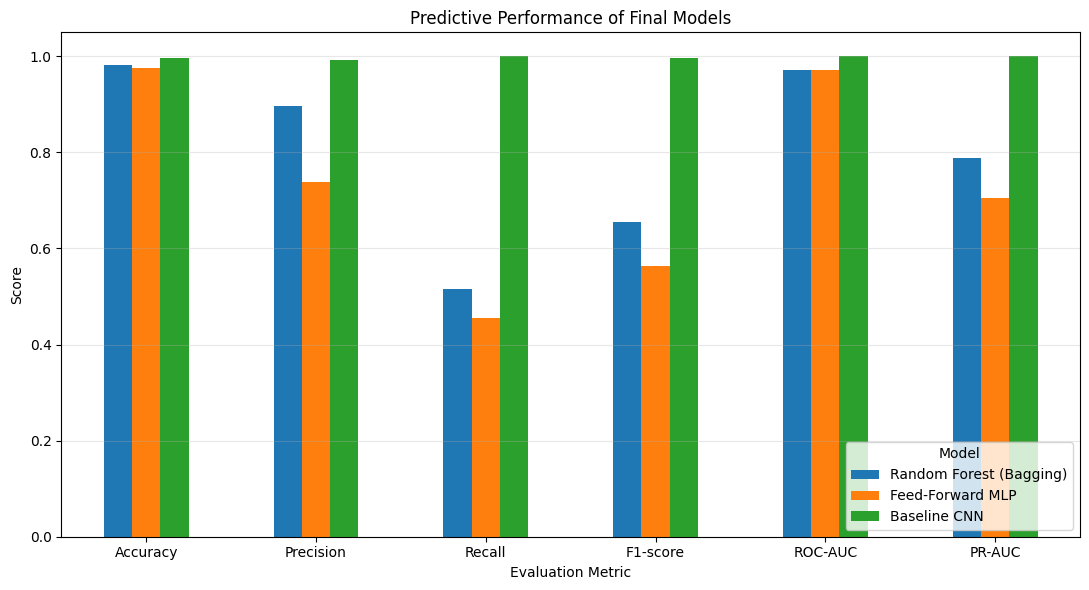

In [ ]:
import matplotlib.pyplot as plt

ax = final_model_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Predictive Performance of Final Models")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Model", loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Training and Computational Cost

In [ ]:
## RANDOM FOREST TRAINING COST
import time
from sklearn.ensemble import RandomForestClassifier

# Temporary Random Forest used only for training-time measurement
rf_timing = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()

rf_timing.fit(X_train_processed, y_train)

rf_training_time = time.perf_counter() - start

print(
    f"Random Forest complete training time: "
    f"{rf_training_time:.4f} seconds"
)

Random Forest complete training time: 1.3657 seconds


In [ ]:
##MLP TRAINING COST
import time
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

# Temporary MLP used only for training-time measurement
mlp_timing = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

mlp_timing.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.perf_counter()

mlp_timing.fit(
    X_train_processed,
    y_train,
    epochs=1,
    batch_size=32,
    verbose=0
)

mlp_single_epoch_time = time.perf_counter() - start

print(
    f"MLP single-epoch training time: "
    f"{mlp_single_epoch_time:.4f} seconds"
)

MLP single-epoch training time: 2.9815 seconds


In [ ]:
##CNN Single Epoch Traininin Cost
import time
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

# Temporary CNN used only for training-time measurement
cnn_timing = Sequential([
    Input(shape=(128, 128, 3)),
    Rescaling(1./255),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(1, activation="sigmoid")
])

cnn_timing.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.perf_counter()

cnn_timing.fit(
    train_dataset,
    epochs=1,
    verbose=0
)

cnn_single_epoch_time = time.perf_counter() - start

print(
    f"CNN single-epoch training time: "
    f"{cnn_single_epoch_time:.4f} seconds"
)

CNN single-epoch training time: 22.2249 seconds


In [ ]:
training_cost_comparison = pd.DataFrame({
    "Measured Training Time (s)": [
        rf_training_time,
        mlp_single_epoch_time,
        cnn_single_epoch_time
    ],

    "Measurement Basis": [
        "Complete model fit",
        "Single training epoch",
        "Single training epoch"
    ]
},
index=[
    "Random Forest (Bagging)",
    "Feed-Forward MLP",
    "Baseline CNN"
])

display(training_cost_comparison.round(4))

,Measured Training Time (s),Measurement Basis
Random Forest (Bagging),1.3657,Complete model fit
Feed-Forward MLP,2.9815,Single training epoch
Baseline CNN,22.2249,Single training epoch


## INFERENCE COST ANALYSIS

In [ ]:
import time
import pandas as pd

# Random Forest inference
start = time.perf_counter()
_ = rf_baseline.predict(X_test_processed)
rf_inference_time = time.perf_counter() - start

rf_ms_per_sample = (
    rf_inference_time / len(X_test_processed)
) * 1000


# MLP inference
start = time.perf_counter()
_ = mlp_model.predict(
    X_test_processed,
    verbose=0
)
mlp_inference_time = time.perf_counter() - start

mlp_ms_per_sample = (
    mlp_inference_time / len(X_test_processed)
) * 1000


# CNN inference
start = time.perf_counter()
_ = baseline_cnn.predict(
    test_dataset,
    verbose=0
)
cnn_inference_time = time.perf_counter() - start

cnn_ms_per_sample = (
    cnn_inference_time / len(y_test_cnn)
) * 1000


# Comparison table
inference_comparison = pd.DataFrame({
    "Total Inference Time (s)": [
        rf_inference_time,
        mlp_inference_time,
        cnn_inference_time
    ],

    "Time per Sample (ms)": [
        rf_ms_per_sample,
        mlp_ms_per_sample,
        cnn_ms_per_sample
    ]
},
index=[
    "Random Forest (Bagging)",
    "Feed-Forward MLP",
    "Baseline CNN"
])

display(inference_comparison.round(4))

,Total Inference Time (s),Time per Sample (ms)
Random Forest (Bagging),0.0789,0.0395
Feed-Forward MLP,0.2431,0.1216
Baseline CNN,1.3015,1.8203


##CRITICAL COMPARSION

In [ ]:
critical_comparison = pd.DataFrame({
    "Random Forest (Bagging)": [
        "Tabular sensor data",
        "High",
        "Low",
        "Low",
        "Strong tabular performance and feature importance"
    ],
    "Feed-Forward MLP": [
        "Tabular sensor data",
        "Low",
        "Moderate",
        "Low",
        "Learns nonlinear relationships but is less interpretable"
    ],
    "Baseline CNN": [
        "Image data",
        "Low",
        "High",
        "High",
        "Excellent visual defect classification"
    ]
},
index=[
    "Data Type",
    "Interpretability",
    "Training Requirement",
    "Inference Requirement",
    "Main Strength"
])

display(critical_comparison)

,Random Forest (Bagging),Feed-Forward MLP,Baseline CNN
Data Type,Tabular sensor data,Tabular sensor data,Image data
Interpretability,High,Low,Low
Training Requirement,Low,Moderate,High
Inference Requirement,Low,Low,High
Main Strength,Strong tabular performance and feature importance,Learns nonlinear relationships but is less int...,Excellent visual defect classification


## 5. SmartFactory Deployment Recommendation


  {Random Forest for Sensor Monitoring:}
    The baseline Random Forest could be employed to monitor sensor
    measurements and identify operating conditions associated with
    machine failure. Its relatively low computational cost and
    feature importance analysis make it suitable for a first-stage
    monitoring system.

   {Class-Weighted MLP as an Early Warning System:}
    The class-weighted MLP could complement the Random Forest
    through its high failure recall, enabling the identification
    of potentially problematic operating conditions. However,
    its low precision indicates that predictions should trigger
    further investigation rather than an automatic production
    shutdown.

  {Baseline CNN for Visual Inspection:}
    The baseline CNN demonstrated superior predictive performance
    compared with CNN v2 and could therefore be employed for
    automated visual inspection of manufactured components.

   {Integration of Sensor-Based and Image-Based Models:}
    A practical SmartFactory implementation could combine
    sensor-based failure prediction with image-based defect
    classification. These components should remain logically
    distinct because they were trained on different datasets
    without paired sensor-image observations.
